# Controlled member-pooling diagnostics

This notebook reads the completed 2016 exploratory run. The target remains the six structural community events. Four LR cells cross community/member-mean features with flat/hierarchical heads, and two HGB cells control the feature effect. Five headline baselines remain unchanged. No fitting occurs in this notebook.

The 2016 period was already observed. Human label review remains pending genuine independent submissions. Main and rolling windows overlap and must be read separately.

In [1]:
# Locate the installed project from either its root or the notebooks directory.
from pathlib import Path
import json
from collections import defaultdict, Counter
import numpy as np
from IPython.display import display, Markdown
from reddit_sna.reporting.diagnostics import read_diagnostics, build_figures
from reddit_sna.pipelines.research import read_table
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/reddit_sna").is_dir())
RUN = ROOT / "artifacts/controlled-pooling/member-pooling-2016-001"
delivery = read_diagnostics(RUN)  # Reject changed payloads before displaying results.
def show_table(headers, rows):
    display(Markdown("| " + " | ".join(headers) + " |\n|" + "---|" * len(headers) + "\n" +
                     "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)))
manifest = delivery["manifest"]
print("Status:", manifest["status"], "Configuration fits:", manifest["configuration_fits"],
      "Internal heads:", manifest["internal_heads"], "Human review:", manifest["human_annotation"])

Status: complete Configuration fits: 126 Internal heads: 168 Human review: pending


## Fixed design and temporal boundaries

Each origin trains only earlier label months. Member means are computed once from causal member bags. LR scaling uses training rows only. Every cell uses the same source targets, split and seeds. The planned candidate is `LR_hier_member_mean`, with no automatic promotion from these inspected outcomes.

In [2]:
# Check recorded fit cutoffs without running any estimator.
fits = json.loads((RUN / "fits.json").read_text())
assert len(fits) == 126 and all(r["latest_train_label"] < r["boundary"] for r in fits)
show_table(["Window", "Boundary", "Train labels through", "Train samples", "Test samples"],
           [[r["window"], r["boundary"], r["latest_train_label"], r["train_n"], r["test_n"]]
            for r in fits if r["seed"] == 42 and r["model"] == "LR_hier_member_mean"])

| Window | Boundary | Train labels through | Train samples | Test samples |
|---|---|---|---|---|
| main | 2016-10 | 2016-09 | 2227 | 494 |
| rolling | 2016-07 | 2016-06 | 1614 | 197 |
| rolling | 2016-08 | 2016-07 | 1811 | 304 |
| rolling | 2016-09 | 2016-08 | 2115 | 112 |
| rolling | 2016-10 | 2016-09 | 2227 | 119 |
| rolling | 2016-11 | 2016-10 | 2346 | 160 |
| rolling | 2016-12 | 2016-11 | 2506 | 215 |

## Coverage and excluded transitions

Resolved community coverage is eligible / (eligible + unresolved). Terminal censored rows are counted separately. Member-month coverage weights current community sizes and repeats users across months. Graph observation coverage uses a separate denominator. `history_missing` describes accepted lineage, not the absence of all member-activity history.

In [3]:
# Show actual denominators, retaining the unresolved population.
rows = [r for r in delivery["coverage"] if r["axis"] in ("all", "size")]
show_table(["Scope", "Observed", "Eligible", "Unresolved", "Censored", "Coverage", "Member coverage"],
           [[r["axis"] + ":" + r["stratum"], r["observed"], r["eligible"], r["unresolved"], r["censored"],
             f"{float(r['coverage']):.2%}", f"{float(r['member_month_coverage']):.2%}"] for r in rows])

| Scope | Observed | Eligible | Unresolved | Censored | Coverage | Member coverage |
|---|---|---|---|---|---|---|
| all:all | 4399 | 2721 | 1678 | 242 | 61.85% | 82.99% |
| size:2 | 2852 | 1696 | 1156 | 163 | 59.47% | 59.47% |
| size:3-4 | 1031 | 662 | 369 | 48 | 64.21% | 64.63% |
| size:5-20 | 365 | 268 | 97 | 18 | 73.42% | 73.95% |
| size:>20 | 151 | 95 | 56 | 13 | 62.91% | 83.31% |

## All recorded comparisons

Fixed-six-class Macro-F1 is averaged across seed-specific scores. Zero seed SD for a deterministic estimator is not evidence of stable population generalization. Archived V4/mean-pooling rows, when available, are historical comparisons on the same keys.

In [4]:
show_table(["Window", "Method", "N per seed", "Macro-F1", "Seed SD"],
           [[r["window"], r["model"], r["n"], f"{float(r['macro_f1_six']):.4f}", f"{float(r['seed_sd']):.4f}"]
            for r in delivery["comparison"]])

| Window | Method | N per seed | Macro-F1 | Seed SD |
|---|---|---|---|---|
| main | A7v4_mean_pool | 494 | 0.3816 | 0.0044 |
| main | B1_majority | 494 | 0.1587 | 0.0000 |
| main | B1_persistence | 494 | 0.1559 | 0.0000 |
| main | B2_random_forest | 494 | 0.2425 | 0.0167 |
| main | B4_logreg | 494 | 0.3250 | 0.0000 |
| main | B5_matched_boosting | 494 | 0.3218 | 0.0000 |
| main | HGB_flat_community | 494 | 0.3777 | 0.0000 |
| main | HGB_flat_member_mean | 494 | 0.3958 | 0.0000 |
| main | HeTCo_v4 | 494 | 0.3468 | 0.0365 |
| main | LR_flat_community | 494 | 0.3223 | 0.0000 |
| main | LR_flat_member_mean | 494 | 0.3234 | 0.0000 |
| main | LR_hier_community | 494 | 0.4249 | 0.0000 |
| main | LR_hier_member_mean | 494 | 0.3963 | 0.0000 |
| rolling | A7v4_mean_pool | 1107 | 0.3523 | 0.0070 |
| rolling | B1_majority | 1107 | 0.1599 | 0.0000 |
| rolling | B1_persistence | 1107 | 0.1562 | 0.0000 |
| rolling | B2_random_forest | 1107 | 0.2122 | 0.0021 |
| rolling | B4_logreg | 1107 | 0.3293 | 0.0000 |
| rolling | B5_matched_boosting | 1107 | 0.2611 | 0.0000 |
| rolling | HGB_flat_community | 1107 | 0.3482 | 0.0000 |
| rolling | HGB_flat_member_mean | 1107 | 0.3752 | 0.0000 |
| rolling | HeTCo_v4 | 1107 | 0.3435 | 0.0037 |
| rolling | LR_flat_community | 1107 | 0.2813 | 0.0000 |
| rolling | LR_flat_member_mean | 1107 | 0.3149 | 0.0000 |
| rolling | LR_hier_community | 1107 | 0.3916 | 0.0000 |
| rolling | LR_hier_member_mean | 1107 | 0.3919 | 0.0000 |

## Aggregate figures

Error bars show seed SD, not confidence intervals. Class recall includes every event even when a class is absent. Monthly scores use six fixed classes, so changes in support matter when interpreting month-to-month differences.

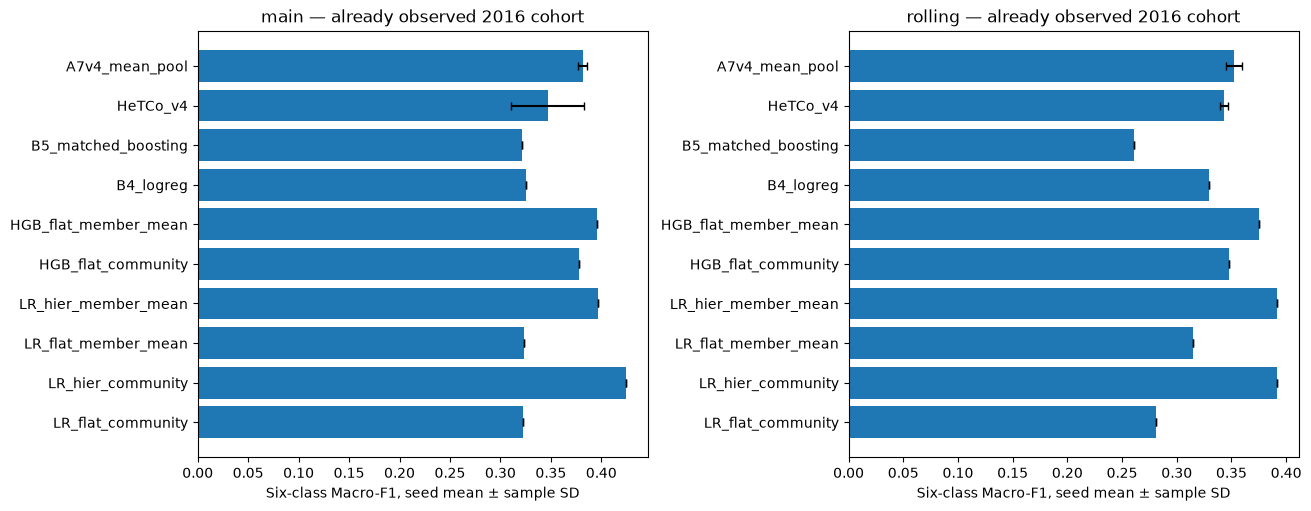

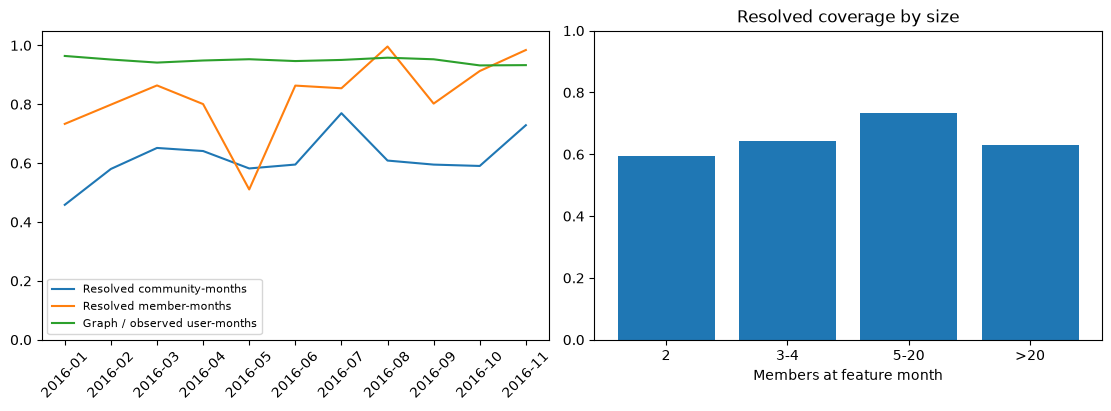

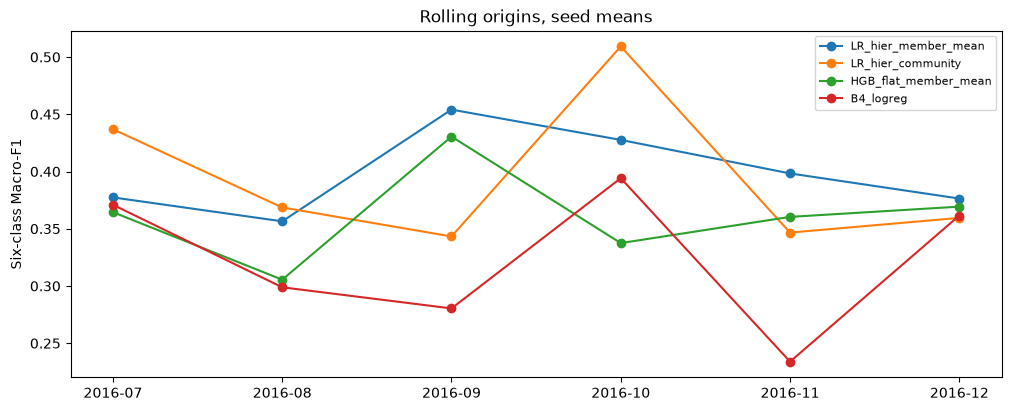

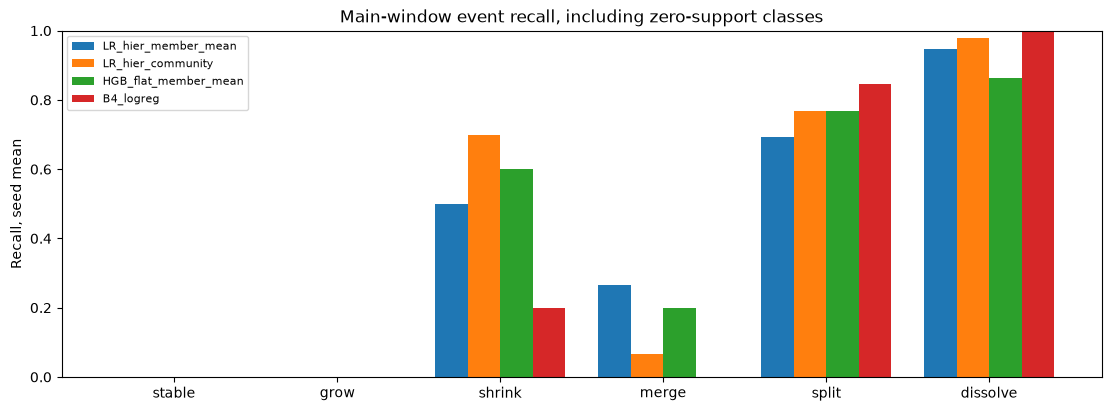

In [5]:
# Figures are rebuilt from saved numeric outputs, not from fitted models.
import matplotlib.pyplot as plt
for name, figure in build_figures(delivery).items():
    display(figure)
    plt.close(figure)

## Prespecified paired contrasts

Member-feature comparisons hold estimator/head fixed. The head comparison holds features fixed. Intervals resample the same contiguous months for both methods and every seed. Fewer than six distinct months produces no month-block interval.

In [6]:
show_table(["Window", "Candidate", "Reference", "Delta", "Month-block interval"],
           [[r["window"], r["proposed"], r["reference"], f"{float(r['delta']):+.4f}",
             f"[{float(r['low']):.4f}, {float(r['high']):.4f}]" if r["low"] else "Unavailable (<6 months)"]
            for r in delivery["intervals"]])

| Window | Candidate | Reference | Delta | Month-block interval |
|---|---|---|---|---|
| main | LR_hier_member_mean | LR_hier_community | -0.0286 | Unavailable (<6 months) |
| main | LR_flat_member_mean | LR_flat_community | +0.0011 | Unavailable (<6 months) |
| main | LR_hier_member_mean | LR_flat_member_mean | +0.0729 | Unavailable (<6 months) |
| main | HGB_flat_member_mean | HGB_flat_community | +0.0181 | Unavailable (<6 months) |
| main | LR_hier_member_mean | B1_majority | +0.2376 | Unavailable (<6 months) |
| main | LR_hier_member_mean | B1_persistence | +0.2403 | Unavailable (<6 months) |
| main | LR_hier_member_mean | B4_logreg | +0.0712 | Unavailable (<6 months) |
| main | LR_hier_member_mean | B2_random_forest | +0.1538 | Unavailable (<6 months) |
| main | LR_hier_member_mean | B5_matched_boosting | +0.0744 | Unavailable (<6 months) |
| rolling | LR_hier_member_mean | LR_hier_community | +0.0002 | [-0.0317, 0.0340] |
| rolling | LR_flat_member_mean | LR_flat_community | +0.0337 | [-0.0070, 0.0471] |
| rolling | LR_hier_member_mean | LR_flat_member_mean | +0.0769 | [0.0715, 0.0942] |
| rolling | HGB_flat_member_mean | HGB_flat_community | +0.0270 | [0.0134, 0.0771] |
| rolling | LR_hier_member_mean | B1_majority | +0.2319 | [0.2131, 0.2796] |
| rolling | LR_hier_member_mean | B1_persistence | +0.2356 | [0.2176, 0.2840] |
| rolling | LR_hier_member_mean | B4_logreg | +0.0625 | [0.0317, 0.1038] |
| rolling | LR_hier_member_mean | B2_random_forest | +0.1797 | [0.1523, 0.2170] |
| rolling | LR_hier_member_mean | B5_matched_boosting | +0.1308 | [0.0972, 0.1534] |

## Original-study error audit

The older full-study cohort uses a separate reference and feature set. Counts below concern the canonical seed, with the other seeds repeating the same cases. Final predictions of dissolve do not by themselves identify which internal head caused an error.

In [7]:
# Publish aggregate errors only, keeping per-case evidence local.
rows = read_table(RUN / "original-paired_cases.csv")
rows = [r for r in rows if r["seed"] == "42" and r["reference"] == "hier_hgb_dynamic"]
counts = Counter(r["outcome"] for r in rows)
show_table(["Outcome", "Unique community-months"], sorted(counts.items()))
show_table(["True event", "Support", "Proposed predicts dissolve", "HGB predicts dissolve"],
           [[event, sum(r["y_true"] == event for r in rows),
             sum(r["y_true"] == event and r["proposed_prediction"] == "dissolve" for r in rows),
             sum(r["y_true"] == event and r["reference_prediction"] == "dissolve" for r in rows)]
            for event in ("grow", "merge")])

| Outcome | Unique community-months |
|---|---|
| both_correct | 1119 |
| both_wrong | 86 |
| proposed_only | 29 |
| reference_only | 35 |

| True event | Support | Proposed predicts dissolve | HGB predicts dissolve |
|---|---|---|---|
| grow | 19 | 14 | 12 |
| merge | 15 | 8 | 9 |

## Interpretation and next decision

Read the matched feature/head contrasts alongside class/month errors and unresolved coverage. Retain adverse results. These runs neither certify an untouched cohort nor replace actual independent human review. The technical review packet remains ready for the assigned reviewers.

Reproduction details are in `docs/RUNBOOK.md`. Executed cells read a completed run and verify its artifact hashes. Choose the project's `.venv` Python kernel in VS Code. GitHub displays the saved cells and plots without executing them.